In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from statsforecast.arima import arima_string

C:\Users\lucas\AppData\Local\pypoetry\Cache\virtualenvs\mcs-red-TMwj_-DE-py3.11\Lib\site-packages\fs\__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)  # type: ignore
C:\Users\lucas\AppData\Local\pypoetry\Cache\virtualenvs\mcs-red-TMwj_-DE-py3.11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
df = pd.read_parquet("../data/clean_foreign_exchange_reserves.parquet")
df.tail()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
7,2020,65.861667,24.295000,27.550833,352.696667,54.590833,88.800833,37.432500,3262.677500,55.978333,...,893.277500,416.920833,68.095000,523.429167,892.870000,7610.353333,90.010000,135.418333,208.609167,8.899167
8,2021,68.871667,26.110000,30.481667,359.058333,58.371667,94.895833,47.328333,3366.054167,58.872500,...,827.308333,456.841667,71.934167,509.424167,987.581667,7982.624167,105.070833,187.279167,218.990833,9.987500
9,2022,81.175833,31.935833,38.776667,341.515833,66.012500,105.453333,44.143333,3293.893333,57.351667,...,971.085833,438.766667,86.178333,621.454167,937.484167,7815.097500,109.914167,240.817500,212.458333,9.538333
10,2023,90.190000,29.365000,37.916667,342.240833,72.271667,113.250833,41.015000,3368.925000,58.023333,...,1141.587500,421.241667,90.910833,639.941667,781.061667,7629.345000,119.994167,244.194167,208.479167,9.898333
11,2024,94.169167,31.460833,38.988333,357.593333,75.389167,121.880000,45.374167,3482.501667,61.644167,...,1153.175833,415.433333,98.212500,662.369167,791.275000,8098.949167,143.194167,243.950000,217.076667,10.151667


In [15]:
df_aus = df[["Year", "Australia"]].copy()

In [16]:
df_aus

,Year,Australia
0,2013,52.751667
1,2014,60.172500
2,2015,62.596667
3,2016,60.568333
4,2017,73.416667
5,2018,71.986667
6,2019,73.037500
7,2020,65.861667
8,2021,68.871667
9,2022,81.175833


<Axes: xlabel='Year', ylabel='Australia'>

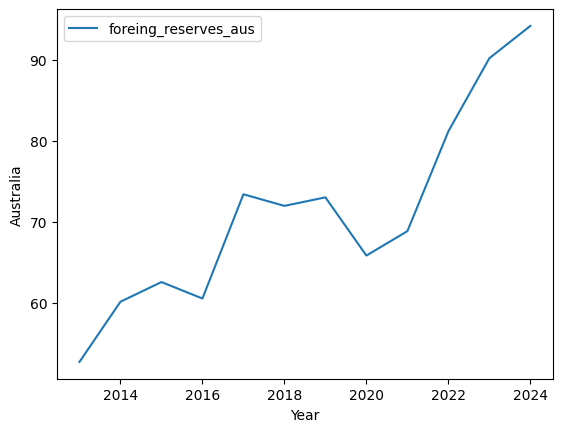

In [17]:
sns.lineplot(df_aus, x='Year', y='Australia', label='foreing_reserves_aus') 

In [18]:
df_aus['unique_id'] = '1'
df_aus.columns=['ds', 'y','unique_id']
df_aus.head()

,ds,y,unique_id
0,2013,52.751667,1
1,2014,60.172500,1
2,2015,62.596667,1
3,2016,60.568333,1
4,2017,73.416667,1


In [19]:
df_aus.dtypes

ds             Int64
y            float64
unique_id     object
dtype: object

In [20]:
df_aus['ds'] = pd.to_datetime(df_aus['ds'].astype(str) + '-01-01')
df_aus.head()

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1


In [22]:
Y_train_df_aus = df_aus[df_aus.ds<='2021-01-01']
Y_test_df_aus = df_aus[df_aus.ds>'2021-01-01']

In [23]:
Y_train_df_aus

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1
5,2018-01-01,71.986667,1
6,2019-01-01,73.037500,1
7,2020-01-01,65.861667,1
8,2021-01-01,68.871667,1


In [24]:
Y_test_df_aus

,ds,y,unique_id
9,2022-01-01,81.175833,1
10,2023-01-01,90.190000,1
11,2024-01-01,94.169167,1


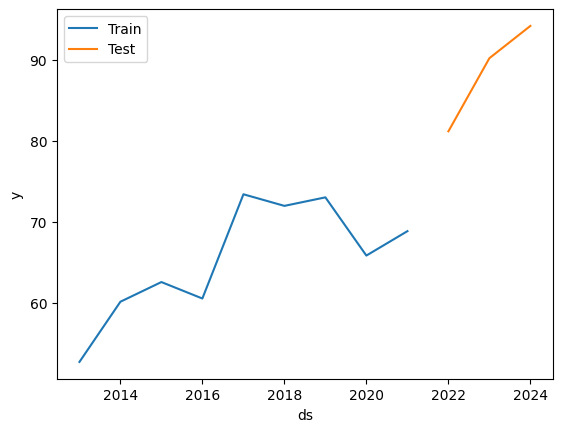

In [25]:
sns.lineplot(Y_train_df_aus, x='ds', y='y', label='Train')
sns.lineplot(Y_test_df_aus, x='ds', y='y', label='Test')
plt.show()

**Why the gap happens**

You're splitting the data at exactly '2021-01-01', so:
- Y_train_df_aus includes data up to and including '2021-01-01'
- Y_test_df_aus includes data after '2021-01-01'

**But here's the catch:** if your original df_aus doesn't have a data point exactly on '2021-01-01', then there's no shared boundary between the two datasets. That creates a visual gap in the plot.


In [26]:
# Instantiating Model

season_length = 1 # yearly data
horizon = len(Y_test_df_aus) # number of predictions

models = [AutoARIMA(season_length=season_length)]

In [27]:
# Initialize StatsForecast with AutoARIMA
sf = StatsForecast(
    models=models,
    freq='YS' # 'YS' for Yearly Start frequency
)

In [28]:
# Fit the model to your data
sf.fit(df=Y_train_df_aus)

StatsForecast(models=[AutoARIMA])

In [29]:
# see the parameters that the model has found
arima_string(sf.fitted_[0,0].model_)

'ARIMA(0,1,0)                   '

In [30]:
# know the values of the terms of our model
result=sf.fitted_[0,0].model_
print(result.keys())
print(result['arma'])

dict_keys(['coef', 'sigma2', 'var_coef', 'mask', 'loglik', 'aic', 'arma', 'residuals', 'code', 'n_cond', 'nobs', 'model', 'bic', 'aicc', 'ic', 'xreg', 'x', 'lambda'])
(0, 0, 0, 0, 1, 1, 0)


In [31]:
residual=pd.DataFrame(result.get("residuals"), columns=["residual Model"])
residual

,residual Model
0,0.052752
1,7.420833
2,2.424167
3,-2.028333
4,12.848333
5,-1.430000
6,1.050833
7,-7.175833
8,3.010000


In [35]:
import scipy.stats as stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

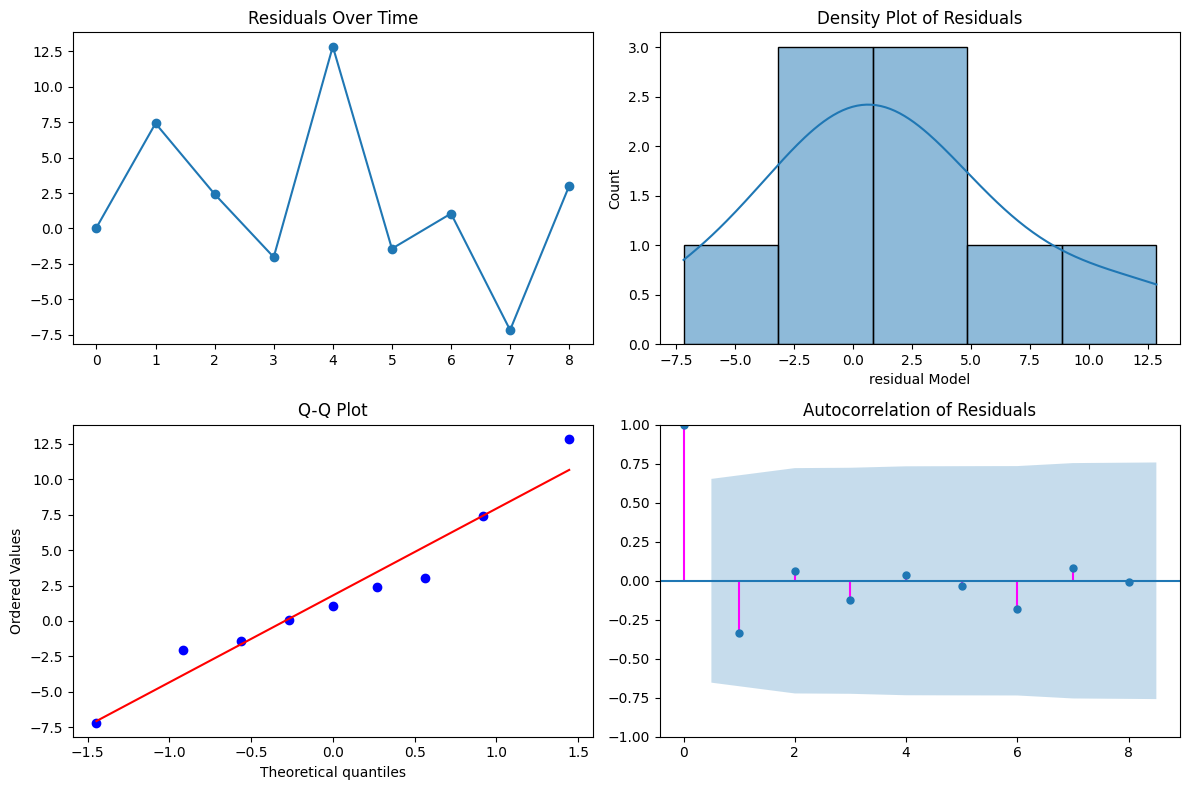

In [40]:
# Extract the residual series
residual_series = residual["residual Model"]

# Set up subplots
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

# 1. Time series plot
axs[0, 0].plot(residual_series, marker='o', linestyle='-')
axs[0, 0].set_title("Residuals Over Time")

# 2. Histogram + KDE
sns.histplot(residual_series, kde=True, ax=axs[0, 1])
axs[0, 1].set_title("Density Plot of Residuals")

# 3. Q-Q plot
stats.probplot(residual_series, dist="norm", plot=axs[1, 0])
axs[1, 0].set_title("Q-Q Plot")

# 4. Autocorrelation plot
plot_acf(residual_series, lags=8, ax=axs[1, 1], vlines_kwargs={"color": "fuchsia"})
axs[1, 1].set_title("Autocorrelation of Residuals")

plt.tight_layout()
plt.show()


**1. Residuals Over Time**
- Purpose: Checks if residuals are randomly scattered.
- Good sign: No visible patterns, trends, or clustering. Just noise.
- Bad sign: Systematic drift or cycles—your model missed something.

**2. Density Plot (Histogram + KDE)**
- Purpose: Shows the distribution of residuals.
- Good sign: Bell-shaped curve centered around zero.
- Bad sign: Skewed or multimodal—suggests non-normal errors.

**3. Q-Q Plot**
- Purpose: Tests if residuals follow a normal distribution.
- Good sign: Points lie close to the diagonal line.
- Bad sign: Curved or scattered points—indicates non-normality.

**4. Autocorrelation Plot (ACF)**
- Purpose: Detects correlation between residuals at different lags.
- Good sign: All bars within confidence bounds—no autocorrelation.
- Bad sign: Significant spikes—model missed temporal structure
- The first bar is lag 0, which means you're comparing each value to itself.
- Since anything is perfectly similar to itself, the correlation is always 1.
- That’s why the first bar is always the tallest—it’s not a problem, just how math works.

In [41]:
# Forecast 3 steps ahead
forecast_df = sf.predict(h=horizon)
print(forecast_df)

  unique_id         ds  AutoARIMA
0         1 2022-01-01  68.871667
1         1 2023-01-01  68.871667
2         1 2024-01-01  68.871667


In [42]:
df_aus

,ds,y,unique_id
0,2013-01-01,52.751667,1
1,2014-01-01,60.172500,1
2,2015-01-01,62.596667,1
3,2016-01-01,60.568333,1
4,2017-01-01,73.416667,1
5,2018-01-01,71.986667,1
6,2019-01-01,73.037500,1
7,2020-01-01,65.861667,1
8,2021-01-01,68.871667,1
9,2022-01-01,81.175833,1


In [44]:
# other prove

models_2 = [AutoARIMA(season_length=season_length, seasonal=True)]
# Initialize StatsForecast with AutoARIMA
sf = StatsForecast(
    models=models_2,
    freq='YS' # 'YS' for Yearly Start frequency
)

In [45]:
# Fit the model to your data
sf.fit(df=Y_train_df_aus)

# see the parameters that the model has found
arima_string(sf.fitted_[0,0].model_)

'ARIMA(0,1,0)                   '

In [47]:
from statsforecast.models import AutoETS

In [48]:
# Implementation of AutoETS with StatsForecast

sf = StatsForecast(models=[AutoETS(model="AZN")], freq='YS')

In [49]:
sf.fit(df=Y_train_df_aus)

StatsForecast(models=[AutoETS])

In [50]:
# Model Prediction
y_hat = sf.predict(h=horizon)
y_hat

,unique_id,ds,AutoETS
0,1,2022-01-01,68.547024
1,1,2023-01-01,68.547024
2,1,2024-01-01,68.547024
